# 2. Erronka – Smart Environment AI: Ikaskuntza automatikoen sistemak (SAA)

**Modulua:** Ikaskuntza automatikoen sistemak · **Zikloa:** IA eta Big Data (FP Santurtzi)

## 1. Sarrera

Cuaderno honetan PIA zatian prestatu ditugun **Mundakako airearen kalitate-datuekin** (Bizkaiko Foru Aldundia) makina-ikaskuntzako ereduak entrenatuko ditugu. Hauek egingo ditugu:

1. Datuak *train*/*test* multzoetan banatu eta aurreko aurreprozesamendua *pipeline* baten barruan erabili.
2. **Erregresioa:** PM10 aurreikusi (erregresio lineal sinplea eta anizkoitza, Ridge eta Lasso) eta MAE, RMSE eta R²-rekin konparatu.
3. **Sailkapena:** airearen kalitate-kategoriak sortu eta KNN, erabaki-zuhaitza eta Naive Bayes konparatu (nahasmen-matrizea, precision, recall eta F1).
4. **Gainbegiratu gabeko ikaskuntza:** K-means aplikatu, *k* aukeratu (elbow eta silhouette) eta klusterrak interpretatu.
5. Eredurik onena aukeratu eta idatziz justifikatu.

## 2. Datuen prestaketa

Datuak PIAn bezala kargatzen ditugu (`;` bereizlea, `latin1` kodeketa, datak `DD/MM/YYYY`), `Month` eta `DayOfWeek` sortzen ditugu eta `O3 8h` zutabea kentzen dugu (%31 huts).

Aurreprozesamendua funtzio batean jarri dugu, eredu bakoitzak berea izan dezan: aldagai zenbakizkoetan mediana (`SimpleImputer`) eta estandarizazioa (`StandardScaler`), eta `Month` eta `DayOfWeek` aldagaietan *one-hot*. Hemen **PCA ez dugu erabiltzen**: osagai nagusiek jatorrizko aldagaiak ezkutatzen dituzte, eta guk erregresioaren koefizienteak interpretatu nahi ditugu. Aurreprozesamendua *pipeline*-aren barruan doanez, *train* multzoarekin bakarrik doitzen da (*data leakage* saihesteko).

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.cluster import KMeans
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, silhouette_score)

plt.style.use('seaborn-v0_8-whitegrid')

# Datuen karga (PIA zatiko pauso berberak)
df = pd.read_csv('MUNDAKA.csv', sep=';', encoding='latin1')
df['Date'] = pd.to_datetime(df['Date'], format='%d/%m/%Y')
df = df.sort_values('Date').reset_index(drop=True)

# Ezaugarri tenporalak eta O3 8h zutabea kendu (%31 huts)
df['Month'] = df['Date'].dt.month
df['DayOfWeek'] = df['Date'].dt.dayofweek
df = df.drop(columns=['O3 8h (µg/m3)'])

print(df.shape)
print(df.isnull().sum())

(306, 9)
Date              0
NO (µg/m3)        4
NOX (µg/m3)       4
NO2 (µg/m3)       4
O3 (µg/m3)        2
PM10 (µg/m3)     49
PM2,5 (µg/m3)     2
Month             0
DayOfWeek         0
dtype: int64


In [3]:
# Aurreprozesamendua (PIAn erabilitakoaren berdina, PCA gabe)
def sortu_aurreprozesamendua(zenbakizkoak, kategorikoak):
    return ColumnTransformer(transformers=[
        ('zenbakizkoak', Pipeline([('imputer', SimpleImputer(strategy='median')),
                                   ('scaler', StandardScaler())]), zenbakizkoak),
        ('kategorikoak', OneHotEncoder(handle_unknown='ignore', sparse_output=False), kategorikoak)
    ])

kategorikoak = ['Month', 'DayOfWeek']

## 3. Erregresioa: PM10 aurreikustea

**PM10**-en kontzentrazioa aurreikusiko dugu gainerako kutsatzaileekin eta denbora-aldagaiekin. PM10 hutsik duten 49 errenkadak kentzen ditugu, helburuaren balioak ez ditugulako asmatu nahi. Datuen %80 entrenatzeko eta %20 probatzeko erabiltzen dugu.

Lau eredu konparatuko ditugu:

- **Erregresio lineal sinplea:** `PM2,5` aldagai bakarrarekin (PM10-ekin korrelaziorik handiena duena, ≈ 0,83).
- **Erregresio lineal anizkoitza:** ezaugarri guztiekin.
- **Ridge** eta **Lasso:** erregularizazioarekin (alpha-ren balioak ez ditugu optimizatu, balio arrunt bat hartu dugu).

In [4]:
# Helburua: PM10. Ezaugarriak: gainerako kutsatzaileak + denbora-aldagaiak
zenb_erreg = ['NO (µg/m3)', 'NOX (µg/m3)', 'NO2 (µg/m3)', 'O3 (µg/m3)', 'PM2,5 (µg/m3)']
df_erreg = df.dropna(subset=['PM10 (µg/m3)'])
X_erreg = df_erreg[zenb_erreg + kategorikoak]
y_erreg = df_erreg['PM10 (µg/m3)']

X_tr, X_te, y_tr, y_te = train_test_split(X_erreg, y_erreg, test_size=0.2, random_state=42)
print(f"Train: {X_tr.shape[0]} errenkada | Test: {X_te.shape[0]} errenkada")

Train: 205 errenkada | Test: 52 errenkada


In [5]:
# Erregresio sinplea: PM2,5 bakarrik; gainerakoak: ezaugarri guztiak
ereduak_erreg = {
    'Erregresio lineal sinplea': (LinearRegression(), ['PM2,5 (µg/m3)'], []),
    'Erregresio lineal anizkoitza': (LinearRegression(), zenb_erreg, kategorikoak),
    'Ridge (alpha=10)': (Ridge(alpha=10), zenb_erreg, kategorikoak),
    'Lasso (alpha=0.1)': (Lasso(alpha=0.1, max_iter=10000), zenb_erreg, kategorikoak),
}

emaitzak_erreg = []
for izena, (eredua, zenb, kat) in ereduak_erreg.items():
    pipe = Pipeline([('aurre', sortu_aurreprozesamendua(zenb, kat)), ('eredua', eredua)])
    pipe.fit(X_tr[zenb + kat], y_tr)
    if izena.startswith('Lasso'):
        lasso_pipe = pipe
    iragarpena = pipe.predict(X_te[zenb + kat])
    emaitzak_erreg.append({
        'Eredua': izena,
        'MAE': mean_absolute_error(y_te, iragarpena),
        'RMSE': np.sqrt(mean_squared_error(y_te, iragarpena)),
        'R²': r2_score(y_te, iragarpena)
    })

emaitzak_erreg = pd.DataFrame(emaitzak_erreg).set_index('Eredua').round(3)
display(emaitzak_erreg)

# Lasso-k zenbat koefiziente utzi dituen zeroan
lasso_koef = lasso_pipe.named_steps['eredua'].coef_
print(f"Lasso: {(lasso_koef == 0).sum()} koefiziente zeroan, {len(lasso_koef)} guztira")

,MAE,RMSE,R²
Eredua,,,
Erregresio lineal sinplea,1.755,2.307,0.705
Erregresio lineal anizkoitza,1.992,2.428,0.673
Ridge (alpha=10),1.830,2.182,0.736
Lasso (alpha=0.1),1.651,2.105,0.754


Lasso: 15 koefiziente zeroan, 23 guztira


**Emaitzen irakurketa:**

- **Lasso da onena** hiru metrikatan: MAE ≈ 1,65 µg/m³, RMSE ≈ 2,11 µg/m³ eta R² ≈ 0,75. PM10-ren batezbestekoa ≈ 11,9 µg/m³ denez, batez beste ≈ 1,7 µg/m³-ko akatsa egiten du.
- **Erregresio anizkoitza sinplea baino okerragoa da** (R² 0,67 vs 0,71). Ezaugarri gehiegi ditugu (*one-hot*-ekin 23 zutabe) 205 entrenamendu-errenkadarentzat, eta batzuk elkarren artean oso lotuta daude (NO, NOX, NO2). Eredua gehiegi doitzen da (*overfitting*).
- **Ridge eta Lasso hobetzen dute**, erregularizazioak koefizienteak txikitzen dituelako. Lasso-k 23 koefizienteetatik 15 zeroan utzi ditu, hau da, informazio gutxi ematen duten aldagaiak kendu ditu. PM2,5 da pisu handiena duen aldagaia.
- **Kontuz:** *test* multzoak 52 errenkada baino ez ditu eta banaketa bakarra egin dugu, beraz eredu artean dagoen diferentzia txikia da (R² 0,71-0,75) eta ez da guztiz sendoa.

## 4. Sailkapena: airearen kalitate-kategoriak

### 4.1. Kategoriak sortzea

Datuetan ez dago kalitate-kategoriarik, beraz guk sortu behar dugu. **O3**-ren eguneko batezbestekoa erabiltzen dugu (kutsatzaile nagusia delako Mundakan) eta lau kategoria definitzen ditugu, enuntziatuan datozenak:

| Kategoria | O3 (µg/m³) |
|---|---|
| Ona | < 60 |
| Onargarria | 60 – 75 |
| Txarra | 75 – 90 |
| Oso txarra | ≥ 90 |

**Oharra:** atalase hauek **ez dira ofizialak**. Mundakako O3 balioetara (33-116 µg/m³) egokitu ditugu, lau kategoriak agertzeko. Benetako sisteman aldundiak edo Europako Ingurumen Agentziak erabiltzen dituen indizeak aplikatu beharko lirateke.

Kategoria O3-rekin sortu dugunez, **O3 ez dugu ezaugarrien artean sartzen** (bestela eredua kategoria definitzen duen arau bera ikasiko luke eta emaitza faltsua izango litzateke).

In [6]:
# Airearen kalitate-kategoriak O3-ren arabera (atalaseak gure datuetara egokituak)
def kategoria_sortu(o3):
    if o3 < 60:
        return 'Ona'
    elif o3 < 75:
        return 'Onargarria'
    elif o3 < 90:
        return 'Txarra'
    else:
        return 'Oso txarra'

kategoria_ordena = ['Ona', 'Onargarria', 'Txarra', 'Oso txarra']

df_sail = df.dropna(subset=['O3 (µg/m3)']).copy()
df_sail['Kalitatea'] = df_sail['O3 (µg/m3)'].apply(kategoria_sortu)
print(df_sail['Kalitatea'].value_counts().reindex(kategoria_ordena))

# O3 ezaugarrietatik kentzen dugu, kategoria berarekin sortu delako (data leakage)
zenb_sail = ['NO (µg/m3)', 'NOX (µg/m3)', 'NO2 (µg/m3)', 'PM10 (µg/m3)', 'PM2,5 (µg/m3)']
X_sail = df_sail[zenb_sail + kategorikoak]
y_sail = df_sail['Kalitatea']

Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(X_sail, y_sail, test_size=0.2, random_state=42, stratify=y_sail)

Kalitatea
Ona            64
Onargarria    112
Txarra        101
Oso txarra     27
Name: count, dtype: int64


### 4.2. Ereduak entrenatu eta konparatu

KNN (k=5), erabaki-zuhaitza (sakonera maximoa 4, gehiegi doitzea saihesteko) eta Naive Bayes entrenatzen ditugu. Metrikak kalkulatzeko `weighted` batezbestekoa erabiltzen dugu, kategoriak ez baitaude orekatuta.

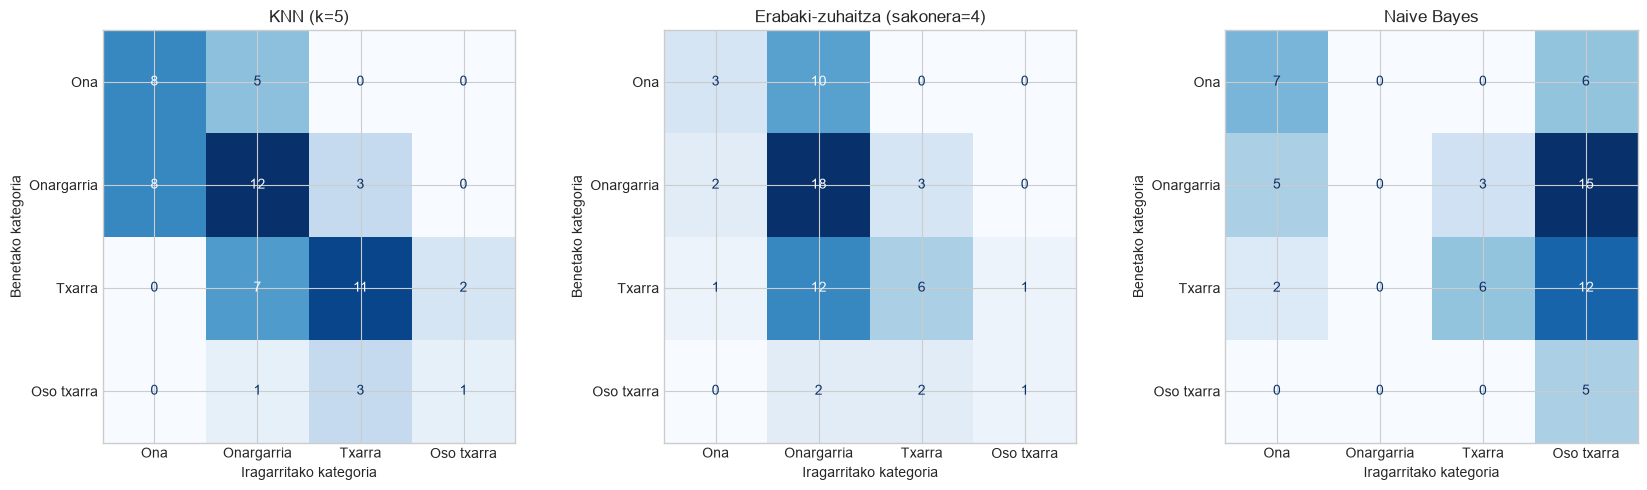

,Accuracy,Precision,Recall,F1
Eredua,,,,
KNN (k=5),0.525,0.527,0.525,0.522
Erabaki-zuhaitza (sakonera=4),0.459,0.488,0.459,0.426
Naive Bayes,0.295,0.336,0.295,0.265


Erreferentzia (klase nagusia beti iragartzea): 0.377
Kalitatea
Onargarria    23
Txarra        20
Ona           13
Oso txarra     5
Name: count, dtype: int64


In [7]:
ereduak_sail = {
    'KNN (k=5)': KNeighborsClassifier(n_neighbors=5),
    'Erabaki-zuhaitza (sakonera=4)': DecisionTreeClassifier(max_depth=4, random_state=42),
    'Naive Bayes': GaussianNB()
}

emaitzak_sail = []
fig, ardatzak = plt.subplots(1, 3, figsize=(17, 5))
for ardatza, (izena, eredua) in zip(ardatzak, ereduak_sail.items()):
    pipe = Pipeline([('aurre', sortu_aurreprozesamendua(zenb_sail, kategorikoak)), ('eredua', eredua)])
    pipe.fit(Xs_tr, ys_tr)
    iragarpena = pipe.predict(Xs_te)
    emaitzak_sail.append({
        'Eredua': izena,
        'Accuracy': accuracy_score(ys_te, iragarpena),
        'Precision': precision_score(ys_te, iragarpena, average='weighted', zero_division=0),
        'Recall': recall_score(ys_te, iragarpena, average='weighted', zero_division=0),
        'F1': f1_score(ys_te, iragarpena, average='weighted', zero_division=0)
    })
    ConfusionMatrixDisplay(confusion_matrix(ys_te, iragarpena, labels=kategoria_ordena),
                           display_labels=kategoria_ordena).plot(ax=ardatza, cmap='Blues', colorbar=False)
    ardatza.set_title(izena)
    ardatza.set_xlabel('Iragarritako kategoria')
    ardatza.set_ylabel('Benetako kategoria')
plt.tight_layout()
plt.show()

emaitzak_sail = pd.DataFrame(emaitzak_sail).set_index('Eredua').round(3)
display(emaitzak_sail)

# Erreferentzia: beti klase nagusia iragartzen balitz
print(f"Erreferentzia (klase nagusia beti iragartzea): {ys_te.value_counts(normalize=True).max():.3f}")
print(ys_te.value_counts())

**Emaitzen irakurketa:**

- **KNN da onena** (accuracy ≈ 0,53, F1 ≈ 0,52), baina emaitzak **ez dira onak**. Klase nagusia beti iragartzeak (≈ 0,38) baino hobea da, baina ez gehiegi.
- **Erabaki-zuhaitza** apur bat okerragoa da (≈ 0,46) eta **Naive Bayes** erreferentzia baino okerragoa (≈ 0,30). Naive Bayes-ek aldagaiak elkarrekiko independenteak direla suposatzen du, eta hemen NO, NOX eta NO2 oso lotuta daude; gainera *one-hot* aldagaiak ez datoz ondo bat banaketa normalarekin.
- **Zergatik da zaila?** O3 prozesu fotokimiko batetik sortzen da eta gainerako kutsatzaileekin ia ez dago lotuta (EDA-n O3 eta NOX artean korrelazioa ≈ 0,02). Urtaroak eragiten dio O3 mailari, beraz `Month` aldagaiak lagun dezake, baina ez da nahikoa.
- **"Oso txarra" kategoriak 5 adibide baino ez ditu *test* multzoan**, beraz kategoria horren emaitzak ez dira fidagarriak.

## 5. Gainbegiratu gabeko ikaskuntza: K-means

Ingurumen-patroiak (egun-motak) aurkitzeko K-means erabiltzen dugu kutsatzaile guztiekin (NO, NOX, NO2, O3, PM10 eta PM2,5), mediana-imputazioa eta estandarizazioa aplikatuta. `Month` ez dugu sartzen, gero kluster bakoitzean zer hilabetetan agertzen den ikusteko.

*k* aukeratzeko bi metodo erabiltzen ditugu: **elbow** (inertzia) eta **silhouette**.

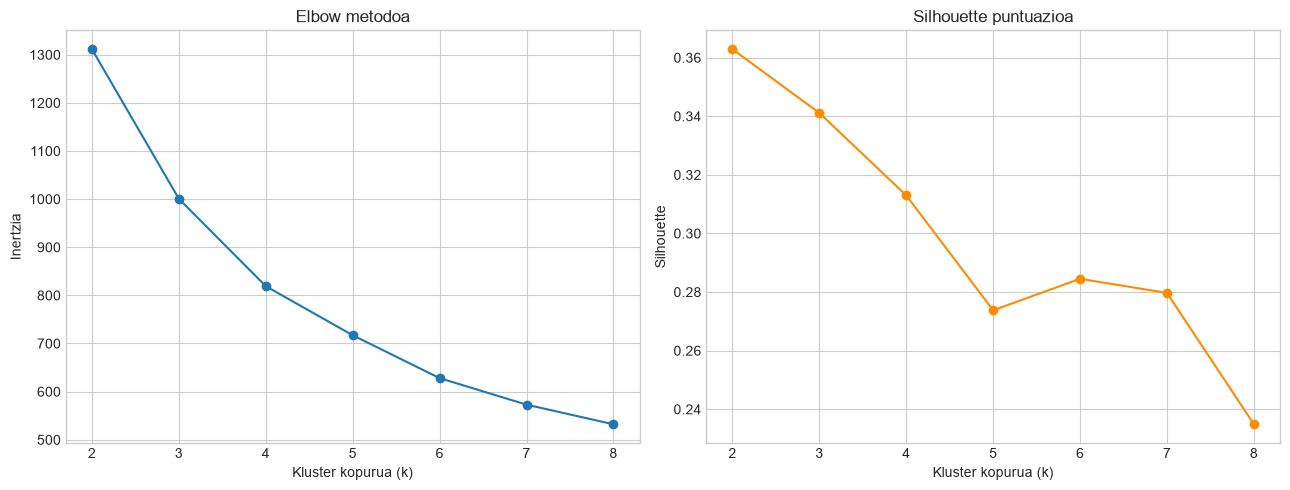

{2: np.float64(0.363), 3: np.float64(0.341), 4: np.float64(0.313), 5: np.float64(0.274), 6: np.float64(0.285), 7: np.float64(0.28), 8: np.float64(0.235)}


In [8]:
# K-means: kutsatzaile-aldagaiekin (hilabetea ez dugu sartzen, gero kluster bakoitzean aztertzeko)
zenb_klust = ['NO (µg/m3)', 'NOX (µg/m3)', 'NO2 (µg/m3)', 'O3 (µg/m3)', 'PM10 (µg/m3)', 'PM2,5 (µg/m3)']
df_klust = df.dropna(subset=zenb_klust, how='all').copy()

aurre_klust = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
X_klust = aurre_klust.fit_transform(df_klust[zenb_klust])

# k aukeratzeko: elbow (inertzia) eta silhouette
k_balioak = range(2, 9)
inertziak, silhouetteak = [], []
for k in k_balioak:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_klust)
    inertziak.append(km.inertia_)
    silhouetteak.append(silhouette_score(X_klust, km.labels_))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5))
a1.plot(list(k_balioak), inertziak, marker='o')
a1.set_title('Elbow metodoa')
a1.set_xlabel('Kluster kopurua (k)')
a1.set_ylabel('Inertzia')
a2.plot(list(k_balioak), silhouetteak, marker='o', color='darkorange')
a2.set_title('Silhouette puntuazioa')
a2.set_xlabel('Kluster kopurua (k)')
a2.set_ylabel('Silhouette')
plt.tight_layout()
plt.show()

print(dict(zip(k_balioak, np.round(silhouetteak, 3))))

**k aukeraketa:** silhouette puntuaziorik handiena *k* = 2 da (0,36), baina *k* = 3 oso gertu dago (0,34). Elbow grafikoan ez dago "ukondo" argirik, inertzia pixkanaka jaisten da. **k = 3 aukeratu dugu**, *k* = 2-rekin kutsatutako egun mota guztiak talde bakarrean nahasten direlako, eta hiruna taldek interpretazio hobea ematen dutelako.

In [9]:
K_AUKERATUA = 3   # goiko bi grafikoen arabera aukeratua

km = KMeans(n_clusters=K_AUKERATUA, random_state=42, n_init=10).fit(X_klust)
df_klust['Klusterra'] = km.labels_

# Kluster bakoitzaren batezbestekoak (interpretaziorako)
print("Kluster bakoitzeko egun kopurua:")
print(df_klust['Klusterra'].value_counts().sort_index())
display(df_klust.groupby('Klusterra')[zenb_klust].mean().round(1))

# Kluster bakoitzeko hilabeteak
display(pd.crosstab(df_klust['Klusterra'], df_klust['Month']))

Kluster bakoitzeko egun kopurua:
Klusterra
0     60
1    200
2     44
Name: count, dtype: int64


,NO (µg/m3),NOX (µg/m3),NO2 (µg/m3),O3 (µg/m3),PM10 (µg/m3),"PM2,5 (µg/m3)"
Klusterra,,,,,,
0,1.2,6.3,4.6,67.5,10.9,4.8
1,0.2,2.8,2.4,68.8,10.1,4.7
2,0.3,4.3,3.9,88.8,19.8,11.4


Month,1,2,3,4,5,6,7,8,9,10,11
Klusterra,,,,,,,,,,,
0,17,12,14,5,0,0,0,0,5,6,1
1,14,15,10,20,23,23,19,30,20,25,1
2,0,1,7,5,8,7,12,0,4,0,0


**Klusterren interpretazioa:**

- **0. klusterra (60 egun) – NOx altuko egunak:** NO, NOX eta NO2 beste klusterretan baino altuagoak dira (NOX ≈ 6,3 µg/m³) eta O3 ez da altua. Egun gehienak urtarriletik martxora eta irailetik azarora daude. Hipotesi gisa, trafikoak edo berokuntzak sortutako kutsadura izan daiteke, hedapen txarreko egunetan pilatua. Hori ezin dugu datu hauekin ziurtatu.
- **1. klusterra (200 egun) – aire garbiko egunak:** kutsatzaile guztiak baxuak dira (NOX ≈ 2,8 µg/m³, PM10 ≈ 10 µg/m³) eta urte osoan zehar agertzen dira. Mundakako egun "normalak" dira.
- **2. klusterra (44 egun) – O3 eta partikula altuko egunak:** O3 (≈ 89 µg/m³), PM10 (≈ 20 µg/m³) eta PM2,5 (≈ 11 µg/m³) altuenak dira. Ia guztiak udaberrian eta udan daude (martxotik irailera). Kutsadura-episodio puntualen seinale izan daiteke, PIA zatiko EDA-n ikusitako ekainaren amaierako pikoen modukoak.

## 6. Eredurik onena aukeratu eta justifikatu

**Aukeratutako eredua: Lasso erregresioa, PM10 aurreikusteko.**

Arrazoiak:

1. **Metrika onenak** ditu: MAE ≈ 1,65, RMSE ≈ 2,11 eta R² ≈ 0,75, hau da, PM10-en aldakortasunaren ≈ %75 azaltzen du.
2. **Erregularizazioak overfitting-a murrizten du:** lineal anizkoitzak baino hobea da datu gutxirekin (205 errenkada) eta aldagai korrelatuekin.
3. **Interpretagarria da:** 23 koefizienteetatik 15 zeroan utzi ditu, eta zein aldagai diren garrantzitsuak ikus daiteke (batez ere PM2,5).
4. **Arina da:** eredu lineal bat da, eta horrek **Jetson Nano**-n exekutatzeko abantaila bat dakar (memoria eta denbora gutxi).

Sailkapen-ereduak baztertu ditugu, **O3-ren kategoria aurreikustea ez baita ondo ateratzen** gure ezaugarriekin (KNN-k, onenak, ≈ %53-ko accuracy du). K-means ez dugu konparatzen, ez baita ikaskuntza gainbegiratua, baina oso baliagarria izan da kutsadura-egun motak identifikatzeko.

**Mugak:** datu gutxi ditugu (306 egun, 2026ko urtea bakarrik), *test* multzoa txikia da eta *train*/*test* banaketa ausazkoa da (eguneko datuak elkarren segidakoak dira, beraz emaitzak apur bat baikorregiak izan daitezke). Hobetzeko, urte gehiagoko datuak eta balidazio gurutzatua erabili beharko genituzke.